[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch13_03_SKOOL_edge_detection_kernel_demo.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 13: Convolution: One Small Window** (Part III: Seeing). This is the kids' course edition of the lab, kept for comparison.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=13](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=13)
* The video course this book grew from: [www.aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# 🔍 Understanding CNN Kernels: Edge Detection Demo

This interactive notebook demonstrates how **convolution kernels** work as edge detectors in Convolutional Neural Networks (CNNs).

## 🎯 Learning Objectives:
- Understand what a kernel/filter is
- See how different kernels detect different types of edges
- Visualize the convolution operation step-by-step
- Upload your own 28×28 images (like kids' drawings!) to test

## 📋 What We'll Cover:
1. Create simple 28×28 test images with edges
2. Apply edge detection kernels (Sobel, Prewitt, Laplacian)
3. **Upload your own images** and detect edges
4. Watch the convolution happen step by step, and see why SciPy and Keras disagree about Sobel's sign

---

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **The edge detector now does what the text says.** Step 2 describes multiply-and-add *without* flipping the kernel, which is what Keras `Conv2D` does (cross-correlation). The code used `scipy.signal.convolve2d`, which flips the kernel first, so every Sobel and Prewitt result had the opposite sign to a CNN. `apply_convolution` now uses `correlate2d`.
> * **New Step 4b**: one output pixel computed by hand, then the same pixel from `correlate2d` (+4) and `convolve2d` (−4), so the flip is something you can see rather than a hidden surprise.
> * The introduction promised an animation of the convolution that was never in the notebook; Step 4b replaces that promise with a step-by-step calculation.
> * Outside Colab you can now set `MY_IMAGE` to your own picture. Emoji were removed from 4 plot titles (Matplotlib's default font cannot draw them; they showed as empty boxes).

## 📦 Step 1: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from scipy import signal
from PIL import Image
import io

# For Google Colab file upload
try:
    from google.colab import files
    IN_COLAB = True
except:
    IN_COLAB = False

# For inline animations in Colab
from IPython.display import HTML, display
from matplotlib import rc
rc('animation', html='jshtml')

print("✅ Libraries imported successfully!")
print(f"📍 Running in Google Colab: {IN_COLAB}")

✅ Libraries imported successfully!
📍 Running in Google Colab: False


---
## 🧠 Step 2: What is a Kernel?

A **kernel** (also called a **filter**) is a small matrix that slides over an image to detect patterns.

### How Convolution Works:
1. Place the kernel on a region of the image
2. Multiply each kernel value with the corresponding pixel
3. Sum all the products → This becomes ONE output pixel
4. Slide the kernel and repeat

Let's define some common edge detection kernels:

In [2]:
# ========================================================================================
# 🔧 EDGE DETECTION KERNELS
# ========================================================================================

# Sobel kernels - detect edges in specific directions
sobel_horizontal = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

sobel_vertical = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

# Prewitt kernels - simpler edge detection
prewitt_horizontal = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

prewitt_vertical = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

# Laplacian kernel - detects edges in ALL directions
laplacian = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0]
], dtype=np.float32)

# Sharpen kernel - enhances edges
sharpen = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

# Store all kernels in a dictionary for easy access
kernels = {
    'Sobel Horizontal': sobel_horizontal,
    'Sobel Vertical': sobel_vertical,
    'Prewitt Horizontal': prewitt_horizontal,
    'Prewitt Vertical': prewitt_vertical,
    'Laplacian': laplacian,
    'Sharpen': sharpen
}

print("✅ Edge detection kernels defined!")

✅ Edge detection kernels defined!


### 👀 Visualize the Kernels

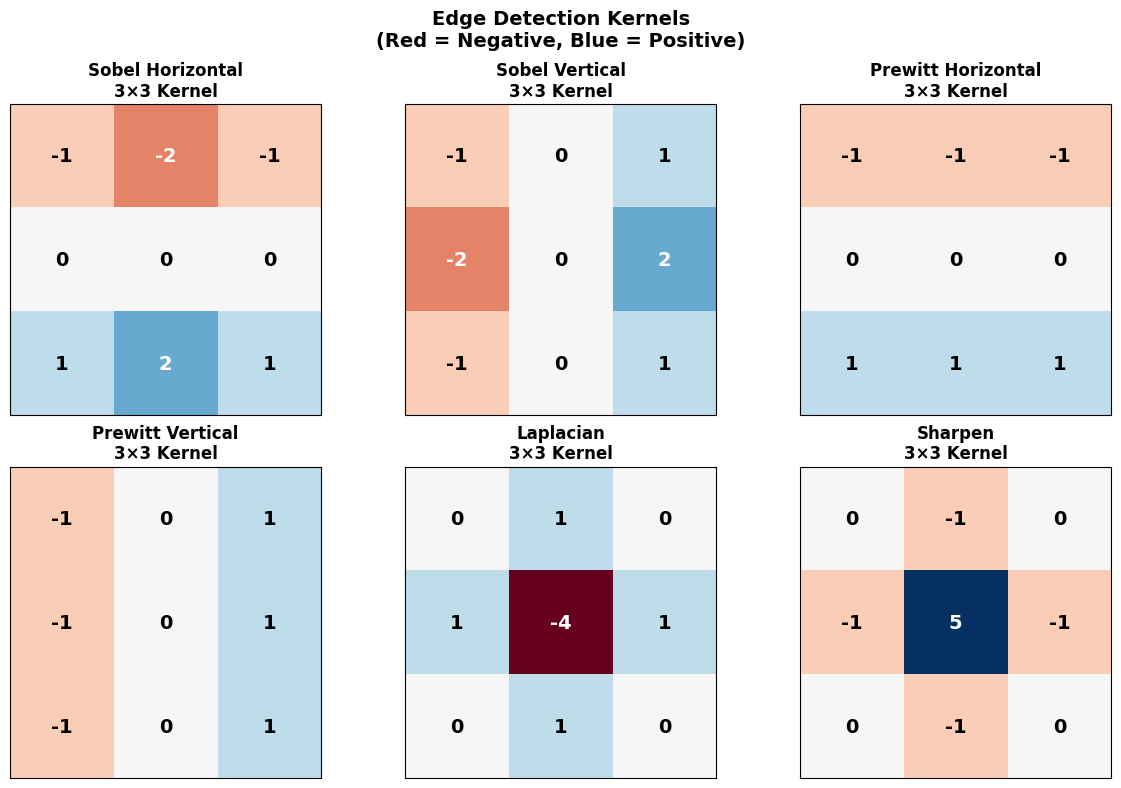


💡 KEY INSIGHT:
   • Sobel/Prewitt kernels have OPPOSITE signs on opposite sides
   • This makes them respond strongly when there's a CHANGE in intensity
   • That change = an EDGE!


In [3]:
# ========================================================================================
# 📊 VISUALIZE ALL KERNELS
# ========================================================================================

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for idx, (name, kernel) in enumerate(kernels.items()):
    ax = axes[idx]
    im = ax.imshow(kernel, cmap='RdBu', vmin=-4, vmax=4)
    ax.set_title(f'{name}\n3×3 Kernel', fontsize=12, fontweight='bold')

    # Add value annotations
    for i in range(3):
        for j in range(3):
            val = kernel[i, j]
            color = 'white' if abs(val) > 1 else 'black'
            ax.text(j, i, f'{val:.0f}', ha='center', va='center',
                   fontsize=14, fontweight='bold', color=color)

    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle('Edge Detection Kernels\n(Red = Negative, Blue = Positive)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("")
print("💡 KEY INSIGHT:")
print("   • Sobel/Prewitt kernels have OPPOSITE signs on opposite sides")
print("   • This makes them respond strongly when there's a CHANGE in intensity")
print("   • That change = an EDGE!")

---
## 🖼️ Step 3: Create Test Images (28×28)

Let's create simple 28×28 images with clear edges to test our kernels.

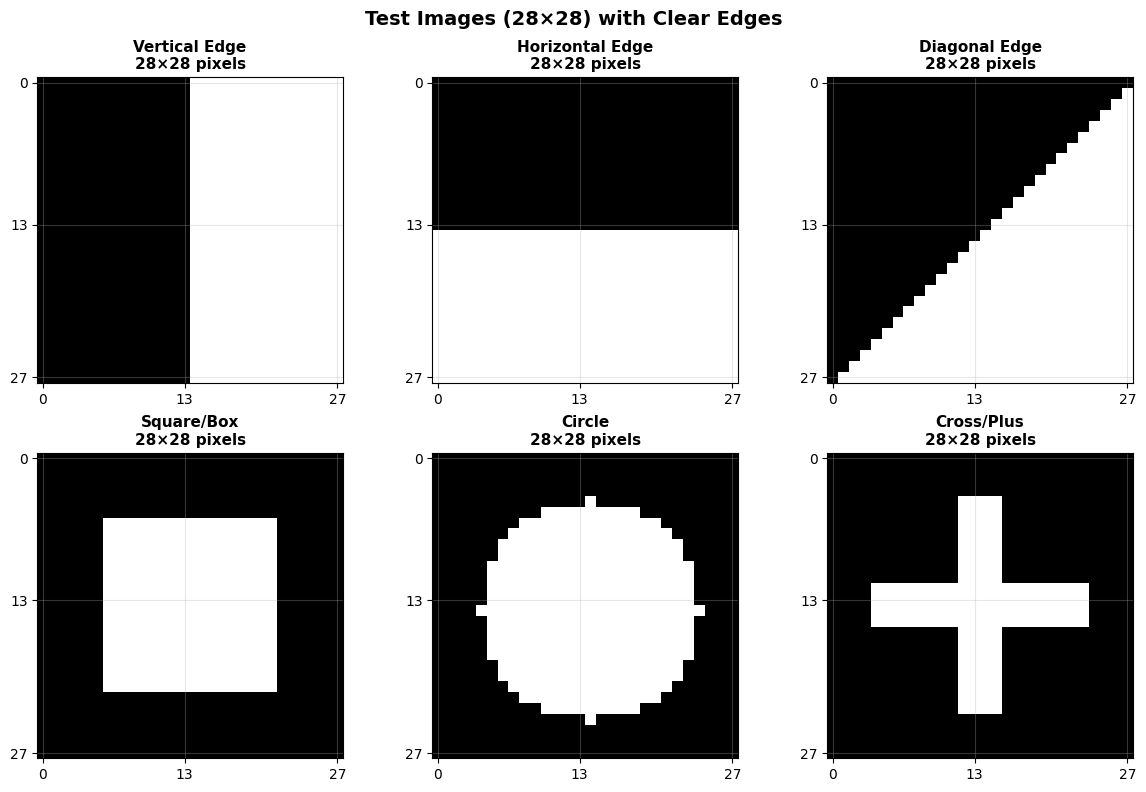

✅ Test images created!


In [4]:
# ========================================================================================
# 🎨 CREATE TEST IMAGES WITH EDGES
# ========================================================================================

def create_test_images():
    """Create various 28x28 test images with different edge patterns."""

    images = {}

    # 1. Vertical Edge (left dark, right bright)
    img = np.zeros((28, 28))
    img[:, 14:] = 1.0
    images['Vertical Edge'] = img

    # 2. Horizontal Edge (top dark, bottom bright)
    img = np.zeros((28, 28))
    img[14:, :] = 1.0
    images['Horizontal Edge'] = img

    # 3. Diagonal Edge
    img = np.zeros((28, 28))
    for i in range(28):
        for j in range(28):
            if i + j > 27:
                img[i, j] = 1.0
    images['Diagonal Edge'] = img

    # 4. Square/Box (like a simple drawing)
    img = np.zeros((28, 28))
    img[6:22, 6:22] = 1.0
    images['Square/Box'] = img

    # 5. Circle (like a ball drawing)
    img = np.zeros((28, 28))
    center = 14
    radius = 10
    for i in range(28):
        for j in range(28):
            if (i - center)**2 + (j - center)**2 <= radius**2:
                img[i, j] = 1.0
    images['Circle'] = img

    # 6. Cross/Plus sign
    img = np.zeros((28, 28))
    img[12:16, 4:24] = 1.0  # Horizontal bar
    img[4:24, 12:16] = 1.0  # Vertical bar
    images['Cross/Plus'] = img

    return images

test_images = create_test_images()

# Visualize test images
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for idx, (name, img) in enumerate(test_images.items()):
    ax = axes[idx]
    ax.imshow(img, cmap='gray')
    ax.set_title(f'{name}\n28×28 pixels', fontsize=11, fontweight='bold')
    ax.set_xticks([0, 13, 27])
    ax.set_yticks([0, 13, 27])
    ax.grid(True, alpha=0.3)

plt.suptitle('Test Images (28×28) with Clear Edges', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("✅ Test images created!")

---
## ⚡ Step 4: Apply Edge Detection Kernels

Now let's see how each kernel detects edges in our test images!

In [5]:
# ========================================================================================
# 🔄 CONVOLUTION FUNCTION
# ========================================================================================

def apply_convolution(image, kernel):
    """Slide the kernel over the image: multiply each kernel value with the pixel under it and add them up.

    This is exactly the recipe in Step 2, and exactly what a Keras Conv2D layer does. Its proper
    mathematical name is CROSS-CORRELATION (scipy.signal.correlate2d). True mathematical convolution
    (scipy.signal.convolve2d) first flips the kernel; Step 4b below shows what that changes.
    """
    return signal.correlate2d(image, kernel, mode='same', boundary='fill', fillvalue=0)

print("✅ Convolution function ready!")

✅ Convolution function ready!


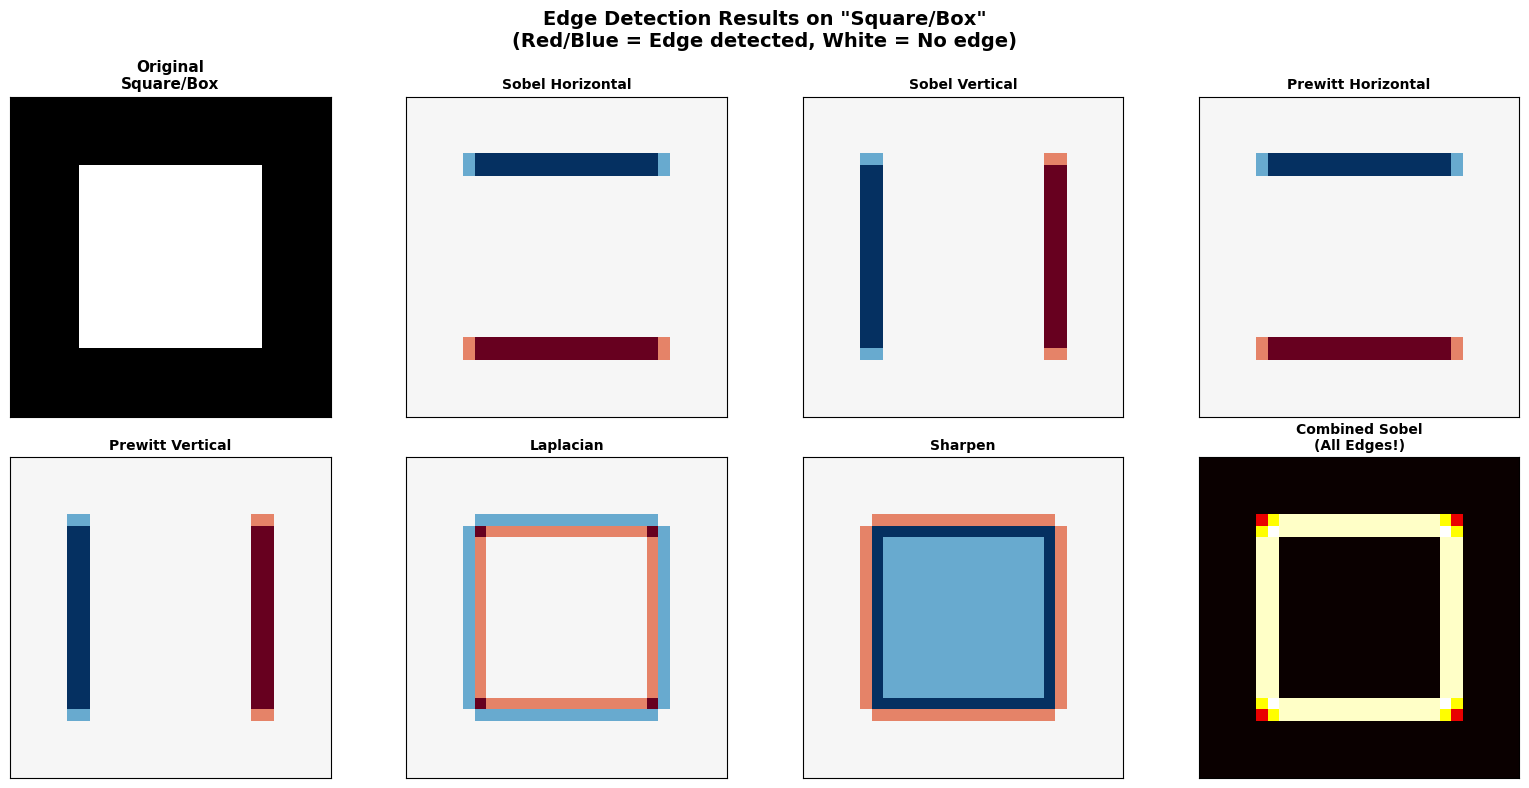


💡 OBSERVATIONS:
   • Sobel Vertical detects LEFT-RIGHT edges (vertical lines)
   • Sobel Horizontal detects TOP-BOTTOM edges (horizontal lines)
   • Combined Sobel shows ALL edges as bright lines!

🔄 Try changing 'selected_image_name' above to test different images!


In [6]:
# ========================================================================================
# 📊 VISUALIZE EDGE DETECTION ON ALL TEST IMAGES
# ========================================================================================

# Select a test image and show all kernel results
selected_image_name = 'Square/Box'  # 🔄 CHANGE THIS to try different images!
selected_image = test_images[selected_image_name]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

# Original image
axes[0, 0].imshow(selected_image, cmap='gray')
axes[0, 0].set_title(f'Original\n{selected_image_name}', fontsize=11, fontweight='bold')
axes[0, 0].set_xticks([])
axes[0, 0].set_yticks([])

# Apply each kernel
kernel_list = list(kernels.items())
positions = [(0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (1, 2)]

for idx, (name, kernel) in enumerate(kernel_list):
    row, col = positions[idx]

    # Apply convolution
    result = apply_convolution(selected_image, kernel)

    # Display result
    im = axes[row, col].imshow(result, cmap='RdBu', vmin=-2, vmax=2)
    axes[row, col].set_title(f'{name}', fontsize=10, fontweight='bold')
    axes[row, col].set_xticks([])
    axes[row, col].set_yticks([])

# Combined edges (Sobel magnitude)
sobel_h = apply_convolution(selected_image, sobel_horizontal)
sobel_v = apply_convolution(selected_image, sobel_vertical)
sobel_magnitude = np.sqrt(sobel_h**2 + sobel_v**2)

axes[1, 3].imshow(sobel_magnitude, cmap='hot')
axes[1, 3].set_title('Combined Sobel\n(All Edges!)', fontsize=10, fontweight='bold')
axes[1, 3].set_xticks([])
axes[1, 3].set_yticks([])

plt.suptitle(f'Edge Detection Results on "{selected_image_name}"\n(Red/Blue = Edge detected, White = No edge)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("")
print("💡 OBSERVATIONS:")
print("   • Sobel Vertical detects LEFT-RIGHT edges (vertical lines)")
print("   • Sobel Horizontal detects TOP-BOTTOM edges (horizontal lines)")
print("   • Combined Sobel shows ALL edges as bright lines!")
print("")
print("🔄 Try changing 'selected_image_name' above to test different images!")

---
## 🔬 Step 4b: One Output Pixel, by Hand

Here is the whole idea in numbers. We put the **Sobel Vertical** kernel on three spots of the *Vertical Edge*
image (dark on the left, bright on the right) and do the multiply-and-add ourselves.

Then a surprise: SciPy has **two** functions for this. `correlate2d` does exactly what we did by hand (and what
Keras does). `convolve2d` first **flips** the kernel, as the mathematical definition of convolution says. For a
lopsided kernel like Sobel, flipping turns it into its own negative, so the edge comes out with the opposite sign.

Sobel Vertical kernel:
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]] 

Centre at row 14, column 5 (flat dark area)
  pixels under the kernel: [[0, 0, 0], [0, 0, 0], [0, 0, 0]]
  multiply and add -> +0

Centre at row 14, column 13 (right on the edge)
  pixels under the kernel: [[0, 0, 1], [0, 0, 1], [0, 0, 1]]
  multiply and add -> +4

Centre at row 14, column 14 (right on the edge)
  pixels under the kernel: [[0, 1, 1], [0, 1, 1], [0, 1, 1]]
  multiply and add -> +4

The same output pixel from SciPy:
  correlate2d (no flip, like Keras) : +4
  convolve2d  (flips the kernel)    : -4

💡 Same magnitude, opposite sign. A flipped Sobel kernel is its own negative.
   For a learnt kernel it makes no difference (training simply learns the flipped one),
   but for a kernel you write by hand, know which one your library computes!


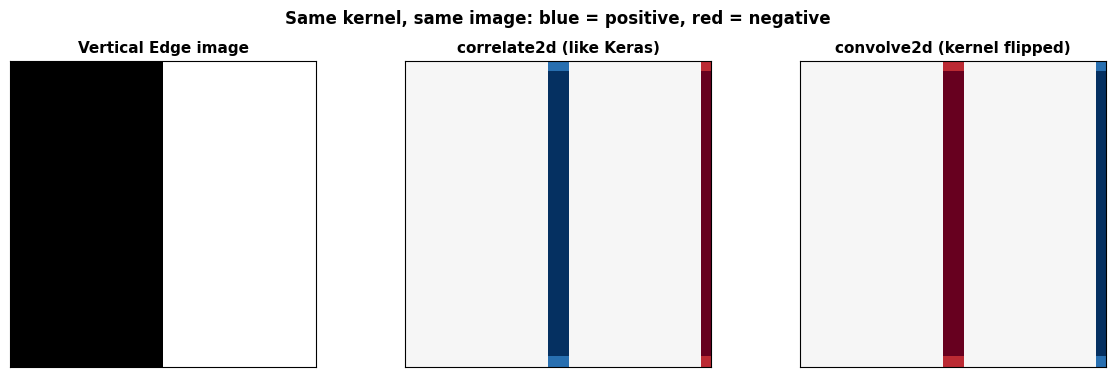

In [7]:
img = test_images['Vertical Edge']
k = sobel_vertical
print("Sobel Vertical kernel:\n", k.astype(int), "\n")
for (r, c) in [(14, 5), (14, 13), (14, 14)]:
    patch = img[r-1:r+2, c-1:c+2]
    out = float((patch * k).sum())
    where = "flat dark area" if c < 13 else "right on the edge"
    print(f"Centre at row {r}, column {c} ({where})")
    print("  pixels under the kernel:", patch.astype(int).tolist())
    print(f"  multiply and add -> {out:+.0f}\n")

r, c = 14, 13
print("The same output pixel from SciPy:")
print(f"  correlate2d (no flip, like Keras) : {signal.correlate2d(img, k, mode='same')[r, c]:+.0f}")
print(f"  convolve2d  (flips the kernel)    : {signal.convolve2d(img, k, mode='same')[r, c]:+.0f}")
print("\n💡 Same magnitude, opposite sign. A flipped Sobel kernel is its own negative.")
print("   For a learnt kernel it makes no difference (training simply learns the flipped one),")
print("   but for a kernel you write by hand, know which one your library computes!")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (title, out) in zip(axes, [('Vertical Edge image', img),
                                   ('correlate2d (like Keras)', signal.correlate2d(img, k, mode='same')),
                                   ('convolve2d (kernel flipped)', signal.convolve2d(img, k, mode='same'))]):
    if title.startswith('Vertical'):
        ax.imshow(out, cmap='gray')
    else:
        ax.imshow(out, cmap='RdBu', vmin=-4, vmax=4)
    ax.set_title(title, fontsize=11, fontweight='bold'); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Same kernel, same image: blue = positive, red = negative', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 📤 Step 5: Upload Your Own Image!

**Upload a drawing from your kids** or any image to see edge detection in action!

The image will be automatically resized to 28×28 pixels.

In [8]:
# ========================================================================================
# 📤 UPLOAD AND PROCESS YOUR OWN IMAGE
# ========================================================================================

def process_uploaded_image(image_data, target_size=(28, 28)):
    """Convert uploaded image to 28x28 grayscale."""

    # Open image
    img = Image.open(io.BytesIO(image_data))

    # Convert to grayscale
    img = img.convert('L')

    # Resize to 28x28
    img = img.resize(target_size, Image.Resampling.LANCZOS)

    # Convert to numpy array and normalize to 0-1
    img_array = np.array(img) / 255.0

    return img_array

def run_edge_detection_on_upload(img_array):
    """Apply all edge detection kernels to the uploaded image."""

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    # Original
    axes[0, 0].imshow(img_array, cmap='gray')
    axes[0, 0].set_title('Your Image\n(28×28)', fontsize=11, fontweight='bold')
    axes[0, 0].set_xticks([])
    axes[0, 0].set_yticks([])

    # Apply kernels
    kernel_list = list(kernels.items())
    positions = [(0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (1, 2)]

    for idx, (name, kernel) in enumerate(kernel_list):
        row, col = positions[idx]
        result = apply_convolution(img_array, kernel)
        axes[row, col].imshow(result, cmap='RdBu', vmin=-2, vmax=2)
        axes[row, col].set_title(f'{name}', fontsize=10, fontweight='bold')
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

    # Combined Sobel
    sobel_h = apply_convolution(img_array, sobel_horizontal)
    sobel_v = apply_convolution(img_array, sobel_vertical)
    sobel_mag = np.sqrt(sobel_h**2 + sobel_v**2)

    axes[1, 3].imshow(sobel_mag, cmap='hot')
    axes[1, 3].set_title('Combined Sobel\n(All Edges!)', fontsize=10, fontweight='bold')
    axes[1, 3].set_xticks([])
    axes[1, 3].set_yticks([])

    plt.suptitle('Edge Detection on Your Uploaded Image!', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

print("✅ Upload functions ready!")
print("")
print("Run the next cell to upload an image...")

✅ Upload functions ready!

Run the next cell to upload an image...


⚠️ File upload works best in Google Colab (or set MY_IMAGE above).
   For local testing, we'll use a test image instead.


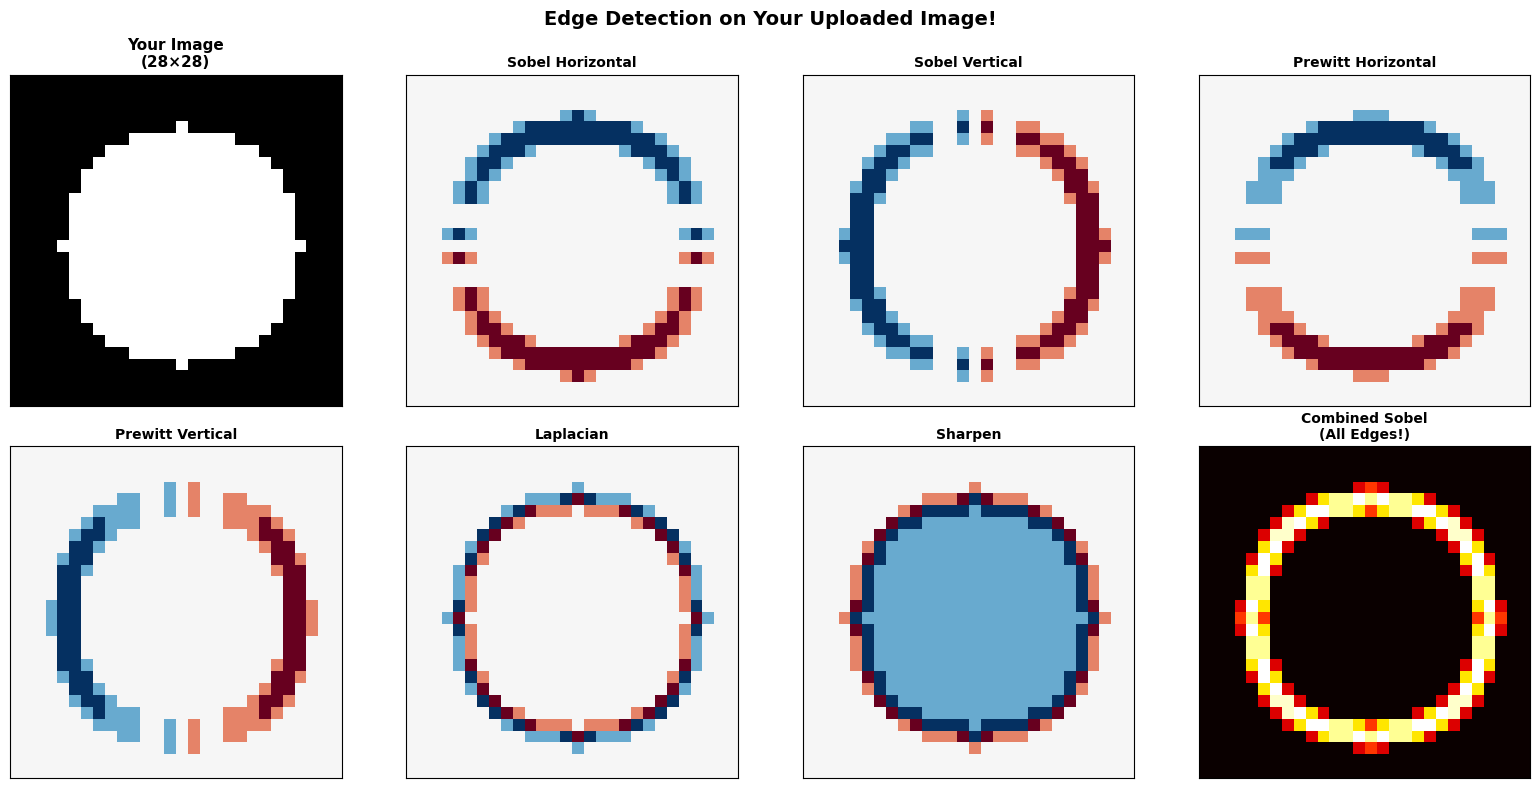

In [9]:
# ========================================================================================
# 📤 UPLOAD YOUR IMAGE HERE!
# ========================================================================================

MY_IMAGE = None   # outside Colab: put the path of your own picture here, e.g. "drawing.png"

if IN_COLAB:
    print("📤 Click 'Choose Files' to upload an image (JPG, PNG, etc.)")
    print("   Great for kids' drawings, doodles, or any picture!")
    print("")

    uploaded = files.upload()

    if uploaded:
        # Get the first uploaded file
        filename = list(uploaded.keys())[0]
        image_data = uploaded[filename]

        print(f"\n✅ Uploaded: {filename}")
        print("⏳ Processing...")

        # Process and display
        img_array = process_uploaded_image(image_data)
        run_edge_detection_on_upload(img_array)

        # Store for later use
        uploaded_image = img_array
        print("\n✅ Image stored as 'uploaded_image' for further experiments!")
elif MY_IMAGE:
    uploaded_image = process_uploaded_image(open(MY_IMAGE, 'rb').read())
    run_edge_detection_on_upload(uploaded_image)
else:
    print("⚠️ File upload works best in Google Colab (or set MY_IMAGE above).")
    print("   For local testing, we'll use a test image instead.")

    # Use a test image
    uploaded_image = test_images['Circle']
    run_edge_detection_on_upload(uploaded_image)

---
## 🎓 Summary

### What We Learned:

1. **Kernels are small matrices** (usually 3×3) that detect specific patterns

2. **Convolution** = sliding the kernel over the image and computing dot products

3. **Edge detection kernels** have opposite signs on opposite sides:
   - This creates high responses where intensity CHANGES (= edges!)
   - Low responses where intensity is UNIFORM

4. **Different kernels detect different edges:**
   - Sobel Vertical → Left-right edges
   - Sobel Horizontal → Top-bottom edges
   - Laplacian → All edges

5. **CNNs LEARN their own kernels** during training:
   - They automatically discover which patterns are useful
   - First layers learn edges, later layers learn complex shapes!

---

### 🚀 Next Steps:
- Try uploading different drawings and see which edges are detected
- Modify the kernel values and see what happens
- Learn how CNN training discovers optimal kernels automatically!

In [10]:
print("🎉 Congratulations! You now understand how CNN kernels detect edges!")
print("")
print("📚 Key Takeaway:")
print("   The 'magic' of CNNs is that they LEARN these kernels automatically")
print("   from data, discovering patterns we might never think to look for!")

🎉 Congratulations! You now understand how CNN kernels detect edges!

📚 Key Takeaway:
   The 'magic' of CNNs is that they LEARN these kernels automatically
   from data, discovering patterns we might never think to look for!
